# Experiment-7: Sentiment Analysis on IMDB Movie Reviews – Logistic Regression vs LSTM vs Transformer vs BERT

Implement sentiment analysis using **Logistic Regression**, **LSTM**, a **Vanilla Transformer** and the pretrained **BERT** model on the IMDB Movie Reviews dataset (50,000 reviews), and perform a comparative analysis using **Precision, Recall, F1** and the **Confusion Matrix**.

Dataset: [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) (same file as in [Ankit152/IMDB-sentiment-analysis](https://github.com/Ankit152/IMDB-sentiment-analysis)).

In [1]:
import os
import re
import time
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 7.1. Loading the dataset

In [2]:
import glob

kaggle_copy = glob.glob("/kaggle/input/**/IMDB Dataset.csv", recursive=True)   # Kaggle dataset, if attached
DATA_FILE = kaggle_copy[0] if kaggle_copy else "IMDB-Dataset.csv"
DATA_URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"

if not os.path.exists(DATA_FILE):          # 66 MB – downloaded once, not committed to the repo
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df = pd.read_csv(DATA_FILE)
print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
df["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

## 7.2. Pre-processing
Remove HTML tags (`<br />`), lower-case, keep letters only. Labels: positive = 1, negative = 0.

In [4]:
def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z']", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()


df["clean"] = df["review"].apply(clean_text)
df["label"] = (df["sentiment"] == "positive").astype(int)
df["length"] = df["clean"].str.split().str.len()

print("Average review length (words):", round(df["length"].mean(), 1))
print("Median review length (words):", int(df["length"].median()))
df[["clean", "label"]].head()

Average review length (words): 229.8
Median review length (words): 172


,clean,label
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming tech...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically there's a family where a little boy ...,0
4,petter mattei's love in the time of money is a...,1


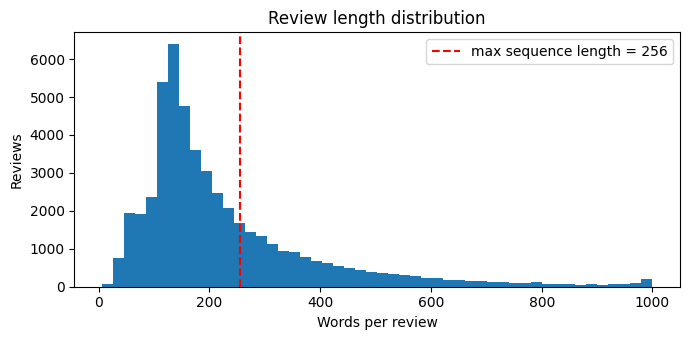

In [5]:
plt.figure(figsize=(7, 3.5))
plt.hist(df["length"].clip(upper=1000), bins=50)
plt.axvline(256, color="red", linestyle="--", label="max sequence length = 256")
plt.xlabel("Words per review")
plt.ylabel("Reviews")
plt.title("Review length distribution")
plt.legend()
plt.tight_layout()
plt.show()

**Train / test split** – 80 / 20, stratified. Every model is evaluated on the **same 10,000 test reviews**.

In [6]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)

y_train = train_df["label"].values
y_test = test_df["label"].values
print("Train:", len(train_df), " Test:", len(test_df))

Train: 40000  Test: 10000


In [7]:
results = {}           # model name -> metrics
predictions = {}       # model name -> predicted labels on the test set


def evaluate(name, y_pred, train_time):
    predictions[name] = y_pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Train time (s)": round(train_time, 1),
    }
    print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3.4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion matrix – {name}")
    plt.tight_layout()
    plt.show()

## 7.3. Logistic Regression (TF-IDF features)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

start = time.time()

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(train_df["clean"])
X_test_tfidf = tfidf.transform(test_df["clean"])

log_reg = LogisticRegression(C=4.0, max_iter=1000)
log_reg.fit(X_train_tfidf, y_train)

lr_time = time.time() - start
print("TF-IDF matrix:", X_train_tfidf.shape)

TF-IDF matrix: (40000, 50000)


              precision    recall  f1-score   support

    negative     0.9181    0.9018    0.9099      5000
    positive     0.9035    0.9196    0.9115      5000

    accuracy                         0.9107     10000
   macro avg     0.9108    0.9107    0.9107     10000
weighted avg     0.9108    0.9107    0.9107     10000



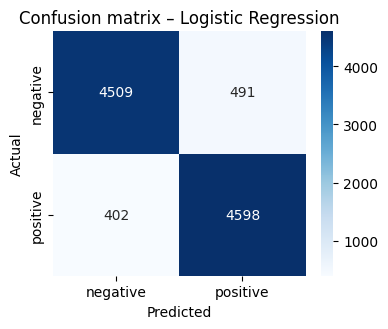

In [9]:
evaluate("Logistic Regression", log_reg.predict(X_test_tfidf), lr_time)

In [10]:
# words with the largest positive / negative weights
feature_names = np.array(tfidf.get_feature_names_out())
order = np.argsort(log_reg.coef_[0])
pd.DataFrame({"Most negative": feature_names[order[:10]], "Most positive": feature_names[order[::-1][:10]]})

,Most negative,Most positive
0,worst,great
1,awful,excellent
2,waste,perfect
3,bad,amazing
4,boring,best
5,poorly,hilarious
6,disappointment,wonderful
7,dull,brilliant
8,terrible,funniest
9,poor,loved


## 7.4. Word-level vocabulary for the neural models
The 20,000 most frequent training words; every review is converted to 256 token ids (padded / truncated). Index 0 = padding, 1 = unknown word.

In [11]:
VOCAB_SIZE = 20000
MAX_LEN = 256

word_counts = Counter(w for text in train_df["clean"] for w in text.split())
itos = ["<pad>", "<unk>"] + [w for w, _ in word_counts.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}


def encode(text):
    ids = [stoi.get(w, 1) for w in text.split()[:MAX_LEN]]
    return ids + [0] * (MAX_LEN - len(ids))


X_train_ids = torch.tensor([encode(t) for t in train_df["clean"]])
X_test_ids = torch.tensor([encode(t) for t in test_df["clean"]])
print(X_train_ids.shape, X_test_ids.shape)

torch.Size([40000, 256]) torch.Size([10000, 256])


In [12]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train_ids, torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_ids, torch.tensor(y_test)), batch_size=256)


def train_model(model, epochs=3, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    for epoch in range(epochs):
        model.train()
        total_loss, correct = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
        history.append((total_loss / len(y_train), correct / len(y_train)))
        print(f"Epoch {epoch + 1}: loss = {history[-1][0]:.4f}, train accuracy = {history[-1][1]:.4f}")
    return history


def predict(model):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in test_loader:
            preds.append(model(xb.to(device)).argmax(1).cpu())
    return torch.cat(preds).numpy()

## 7.5. LSTM
Embedding → bidirectional LSTM → last hidden states of both directions → linear classifier.

In [13]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(2 * hidden_dim, num_classes)

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.embedding(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        hidden = torch.cat([h_n[-2], h_n[-1]], dim=1)      # forward + backward final states
        return self.fc(self.dropout(hidden))


torch.manual_seed(SEED)
lstm_model = LSTMClassifier(VOCAB_SIZE)
print(lstm_model)
print("Parameters:", sum(p.numel() for p in lstm_model.parameters()))

LSTMClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)
Parameters: 2824706


In [14]:
start = time.time()
lstm_history = train_model(lstm_model, epochs=3)
lstm_time = time.time() - start

Epoch 1: loss = 0.5405, train accuracy = 0.7185
Epoch 2: loss = 0.3843, train accuracy = 0.8313
Epoch 3: loss = 0.2801, train accuracy = 0.8859


              precision    recall  f1-score   support

    negative     0.8369    0.9052    0.8697      5000
    positive     0.8968    0.8236    0.8586      5000

    accuracy                         0.8644     10000
   macro avg     0.8668    0.8644    0.8642     10000
weighted avg     0.8668    0.8644    0.8642     10000



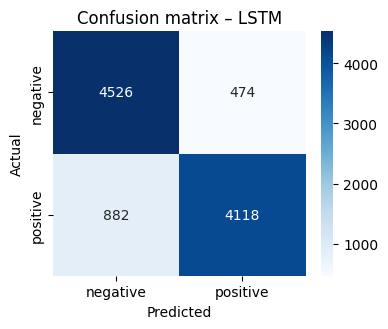

In [15]:
evaluate("LSTM", predict(lstm_model), lstm_time)

## 7.6. Vanilla Transformer (encoder, trained from scratch)
Token embedding + learned positional embedding → 2 Transformer encoder layers (multi-head self-attention, 4 heads) → mean pooling over the non-padding tokens → linear classifier.

In [16]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=2, ff_dim=256, max_len=MAX_LEN, num_classes=2):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.position_embedding = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, ff_dim, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        pad_mask = x == 0
        positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        h = self.token_embedding(x) + self.position_embedding(positions)
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        keep = (~pad_mask).unsqueeze(-1).float()
        pooled = (h * keep).sum(1) / keep.sum(1).clamp(min=1)      # mean over real tokens
        return self.fc(self.dropout(pooled))


torch.manual_seed(SEED)
transformer_model = TransformerClassifier(VOCAB_SIZE)
print("Parameters:", sum(p.numel() for p in transformer_model.parameters()))

Parameters: 2857986


In [17]:
start = time.time()
transformer_history = train_model(transformer_model, epochs=3, lr=5e-4)
transformer_time = time.time() - start

Epoch 1: loss = 0.4928, train accuracy = 0.7521
Epoch 2: loss = 0.3342, train accuracy = 0.8558
Epoch 3: loss = 0.2637, train accuracy = 0.8930


              precision    recall  f1-score   support

    negative     0.8390    0.8870    0.8623      5000
    positive     0.8801    0.8298    0.8542      5000

    accuracy                         0.8584     10000
   macro avg     0.8596    0.8584    0.8583     10000
weighted avg     0.8596    0.8584    0.8583     10000



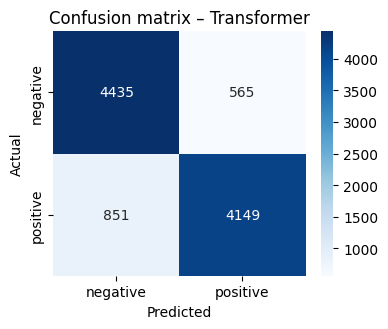

In [18]:
evaluate("Transformer", predict(transformer_model), transformer_time)

## 7.7. BERT (pretrained `bert-base-uncased`, fine-tuned)
BERT is already pretrained on BooksCorpus + Wikipedia, so only a short fine-tuning is needed: **1 epoch** on the same 40,000 training reviews, evaluated on the same 10,000 test reviews. The raw review text (HTML removed) is fed to BERT's own WordPiece tokenizer. On a GPU, mixed precision (fp16) is used for speed; without a GPU the training set is cut to 8,000 reviews to keep the run practical.

In [19]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

BERT_TRAIN_SIZE = len(train_df) if device == "cuda" else 8000
bert_train_df = train_df.sample(BERT_TRAIN_SIZE, random_state=SEED)
use_amp = device == "cuda"
print("BERT training reviews:", BERT_TRAIN_SIZE, "| mixed precision:", use_amp)
strip_html = lambda t: re.sub(r"<.*?>", " ", t)

example = bert_tokenizer.tokenize(strip_html(bert_train_df["review"].iloc[0]))[:20]
print(example)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT training reviews: 40000 | mixed precision: True
['why', ',', 'oh', 'why', ',', 'is', 'this', 'trash', 'considered', 'a', 'classic', '?', 'i', "'", 've', 'seen', 'higher', 'body', 'counts', 'on']


In [20]:
def bert_batches(texts, labels, batch_size, shuffle):
    order = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for start in range(0, len(texts), batch_size):
        idx = order[start:start + batch_size]
        enc = bert_tokenizer([strip_html(texts[i]) for i in idx], truncation=True,
                             max_length=MAX_LEN, padding=True, return_tensors="pt")
        yield {k: v.to(device) for k, v in enc.items()}, torch.tensor(labels[idx]).to(device)


torch.manual_seed(SEED)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_name, num_labels=2).to(device)

BERT_BATCH = 16
steps = BERT_TRAIN_SIZE // BERT_BATCH + 1
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * steps), steps)

bert_texts = bert_train_df["review"].values
bert_labels = bert_train_df["label"].values

scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

start = time.time()
bert_model.train()
running_loss = []
for step, (inputs, labels) in enumerate(bert_batches(bert_texts, bert_labels, BERT_BATCH, shuffle=True), 1):
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
        loss = bert_model(**inputs, labels=labels).loss
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()
    optimizer.zero_grad()
    running_loss.append(loss.item())
    if step % 250 == 0:
        print(f"step {step}/{steps}: loss (last 250) = {np.mean(running_loss[-250:]):.4f}")
bert_time = time.time() - start

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step 250/2501: loss (last 250) = 0.5145
step 500/2501: loss (last 250) = 0.2747
step 750/2501: loss (last 250) = 0.2559
step 1000/2501: loss (last 250) = 0.2679
step 1250/2501: loss (last 250) = 0.2451
step 1500/2501: loss (last 250) = 0.2253
step 1750/2501: loss (last 250) = 0.2338
step 2000/2501: loss (last 250) = 0.2205
step 2250/2501: loss (last 250) = 0.2112
step 2500/2501: loss (last 250) = 0.2087


              precision    recall  f1-score   support

    negative     0.9358    0.9128    0.9242      5000
    positive     0.9149    0.9374    0.9260      5000

    accuracy                         0.9251     10000
   macro avg     0.9254    0.9251    0.9251     10000
weighted avg     0.9254    0.9251    0.9251     10000



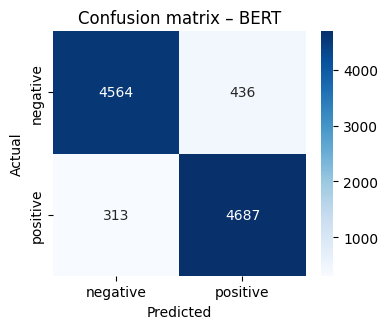

In [21]:
bert_model.eval()
bert_preds = []
with torch.no_grad():
    for inputs, _ in bert_batches(test_df["review"].values, y_test, 64, shuffle=False):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            bert_preds.append(bert_model(**inputs).logits.argmax(1).cpu())
bert_preds = torch.cat(bert_preds).numpy()

evaluate("BERT", bert_preds, bert_time)

## 7.8. Comparative analysis

In [22]:
comparison = pd.DataFrame(results).T
comparison["Training reviews"] = [f"{len(train_df):,}"] * 3 + [f"{BERT_TRAIN_SIZE:,}"]
comparison.style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}) \
    .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1"], color="#c6efce")

,Accuracy,Precision,Recall,F1,Train time (s),Training reviews
Logistic Regression,0.9107,0.9035,0.9196,0.9115,26.000000,"40,000"
LSTM,0.8644,0.8968,0.8236,0.8586,63.700000,"40,000"
Transformer,0.8584,0.8801,0.8298,0.8542,63.100000,"40,000"
BERT,0.9251,0.9149,0.9374,0.9260,575.200000,"40,000"


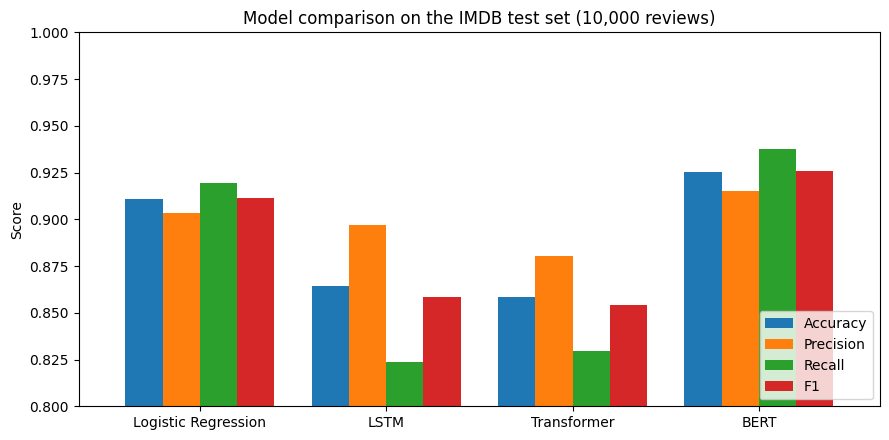

In [23]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
ax = comparison[metrics].astype(float).plot(kind="bar", figsize=(9, 4.5), width=0.8)
ax.set_ylim(0.8, 1.0)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the IMDB test set (10,000 reviews)")
ax.set_xticklabels(comparison.index, rotation=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

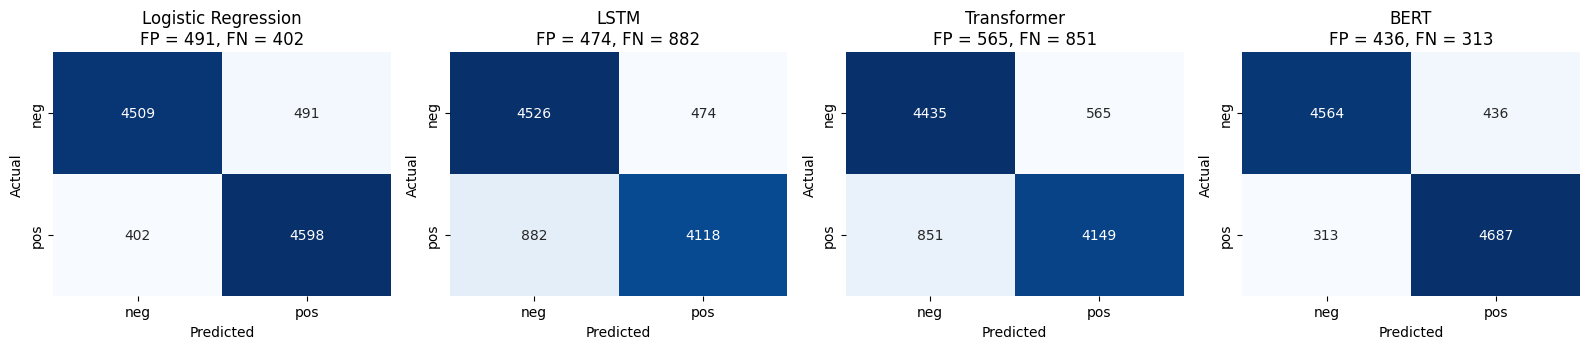

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(f"{name}\nFP = {cm[0, 1]}, FN = {cm[1, 0]}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [25]:
# the same new reviews through every model
samples = [
    "An absolute masterpiece. The acting was brilliant and the story kept me hooked till the end.",
    "Total waste of time. The plot made no sense and the dialogue was painfully bad.",
    "I expected to hate it, but it turned out to be surprisingly good.",
    "Not bad at all, though the ending was a bit disappointing.",
]

def predict_all(text):
    clean = clean_text(text)
    ids = torch.tensor([encode(clean)]).to(device)
    enc = bert_tokenizer(text, return_tensors="pt").to(device)
    label = lambda p: "positive" if p == 1 else "negative"
    with torch.no_grad():
        return {
            "Logistic Regression": label(log_reg.predict(tfidf.transform([clean]))[0]),
            "LSTM": label(lstm_model(ids).argmax(1).item()),
            "Transformer": label(transformer_model(ids).argmax(1).item()),
            "BERT": label(bert_model(**enc).logits.argmax(1).item()),
        }

lstm_model.eval(); transformer_model.eval()
pd.DataFrame([{"Review": s, **predict_all(s)} for s in samples])

,Review,Logistic Regression,LSTM,Transformer,BERT
0,An absolute masterpiece. The acting was brilli...,positive,positive,positive,positive
1,Total waste of time. The plot made no sense an...,negative,negative,negative,negative
2,"I expected to hate it, but it turned out to be...",positive,positive,positive,positive
3,"Not bad at all, though the ending was a bit di...",negative,negative,negative,negative


### Observations

Run on a Kaggle T4 GPU. All models are tested on the same 10,000 reviews (5,000 positive, 5,000 negative).

| Model | Accuracy | Precision | Recall | F1 | False positives | False negatives | Train time |
|---|---|---|---|---|---|---|---|
| Logistic Regression (TF-IDF) | 0.9107 | 0.9035 | 0.9196 | 0.9115 | 491 | 402 | 26 s |
| LSTM (bidirectional) | 0.8644 | 0.8968 | 0.8236 | 0.8586 | 474 | 882 | 64 s |
| Transformer (from scratch) | 0.8584 | 0.8801 | 0.8298 | 0.8542 | 565 | 851 | 63 s |
| **BERT (fine-tuned)** | **0.9251** | **0.9149** | **0.9374** | **0.9260** | **436** | **313** | 575 s |

- **BERT is the best model on every metric** (F1 0.926) and makes the fewest mistakes in both directions. Its pretraining on large text corpora gives it word meanings and context (negation, "not bad", sarcasm) before it sees a single review, so one epoch of fine-tuning is enough.
- **Logistic Regression is a very strong baseline** (F1 0.912, only 1.5 points behind BERT) and trains about 20× faster. Sentiment in movie reviews is carried largely by individual words and bigrams ("waste", "worst", "highly recommend"), which TF-IDF captures directly.
- **LSTM and the Transformer trained from scratch score lowest** (F1 about 0.86). With 40,000 reviews and 3 epochs they have to learn word meanings from zero, and both truncate reviews to 256 words. Their confusion matrices show the same bias: high precision but low recall on the positive class, so they label about 850–880 positive reviews as negative.
- **LSTM vs Transformer:** almost identical results. Self-attention has no advantage over recurrence at this data size without pretraining. The Transformer's advantage appears once it is pretrained, which is exactly what BERT is.
- **Trade-off:** BERT costs about 20× the training time of Logistic Regression and needs a GPU, for a gain of about 1.5 F1 points. When speed or interpretability matters, TF-IDF + Logistic Regression is the practical choice. When accuracy matters, use a pretrained Transformer.